---
title: "Asymptotics, WKB and Bessel Functions"
short_title: "Q-M5 Asymptotics, WKB & Bessel"
numbering:
  heading_2: true
  equation: true
---

# Asymptotics, WKB and Bessel Functions

:::{tip} Where this sits in the plan
Math for **variational and WKB methods** and **scattering** (quantum topics 9 and 11). Calculus of variations is in mechanics M5 and Fourier transforms in E&M E-M3; this notebook adds approximation methods for ODEs and the special functions of three-dimensional waves.

| Item | Stewart | Boas | Zill | Arfken |
|---|---|---|---|---|
| Asymptotic methods and WKB | – | 1 | – | 12 |
| Second-order linear ODEs | 17 | 8 | 3 | 7 |
| Bessel functions | – | 12 | 5, 14 | 14 |
| Legendre polynomials (plane-wave expansion) | – | 12 | 5, 14 | 15 |

Chapter numbers are approximate, as in the workbook.
:::

Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy import special

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
hbar = 1.054572e-34    # J s
m_e = 9.10938e-31      # kg
eV = 1.602177e-19      # J
a0 = 5.29177e-11       # m (Bohr radius)
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Asymptotic Behavior

Before solving an ODE, ask what the solution does where one term dominates. For $\psi'' = (\xi^2 - K)\psi$ at large $\xi$, the $K$ is negligible and $\psi\sim e^{\pm\xi^2/2}$ (Q-M2). For the hydrogen radial equation at large $r$, $\psi\sim e^{\pm\kappa r}$; near $r = 0$, $\psi\sim r^{\ell+1}$ or $r^{-\ell}$. Keeping only the well-behaved pieces and factoring them out is the first step of every exact solution in the quantum book.

An **asymptotic series** goes further: $f(x)\sim\sum a_n/x^n$ as $x\to\infty$, where each truncation gets better as $x$ grows, even if the series diverges for every fixed $x$. Stirling's series for $\ln N!$ (T-M1) is one; WKB is another.

## The WKB Approximation

Write the time-independent Schrödinger equation as

$$
\psi'' = -\frac{p(x)^2}{\hbar^2}\psi,\qquad p(x) = \sqrt{2m\left(E - V(x)\right)} .
$$ (eq-schrodinger-p)

If $V$ were constant, $\psi = e^{\pm ipx/\hbar}$. If $V$ changes slowly compared with the local wavelength $\lambda = h/p$, guess a wave with slowly varying amplitude and wavenumber.

:::{prf:theorem} WKB solutions
:label: thm-wkb

Where $E > V$ (classically allowed),

$$
\psi(x)\approx\frac{C}{\sqrt{p(x)}}\exp\!\left(\pm\frac i\hbar\int^xp(x')\,dx'\right) ;
$$ (eq-wkb-allowed)

where $E < V$ (forbidden), with $|p| = \sqrt{2m(V - E)}$,

$$
\psi(x)\approx\frac{C}{\sqrt{|p(x)|}}\exp\!\left(\pm\frac1\hbar\int^x|p(x')|\,dx'\right) .
$$ (eq-wkb-forbidden)

Valid where $|d\lambda/dx|\ll1$: the wavelength changes little over one wavelength.
:::

:::{prf:proof}
:class: dropdown

Substitute $\psi = Ae^{i\phi}$ with real $A$, $\phi$ and separate real and imaginary parts:

$$
A'' - A(\phi')^2 = -\frac{p^2}{\hbar^2}A,\qquad (A^2\phi')' = 0 .
$$

The second gives $A\propto1/\sqrt{\phi'}$ exactly. The approximation is dropping $A''$ in the first (slowly varying amplitude), which leaves $\phi' = \pm p/\hbar$, so $A\propto1/\sqrt p$.
:::

The $1/\sqrt p$ amplitude has a classical meaning: $|\psi|^2\propto1/p\propto1/v$, the fraction of time a classical particle spends near $x$.

### Turning points and the quantization rule

At a **turning point** $V = E$, $p\to0$ and WKB fails. Near there, $V$ is nearly linear, and the exact solution of $\psi'' = \alpha x\psi$ is the **Airy function** $\mathrm{Ai}$. Matching Airy's two asymptotic forms to the WKB solutions on either side (the connection formulas) gives, for a well with two smooth turning points $a$ and $b$,

$$
\int_a^bp(x)\,dx = \left(n + \tfrac12\right)\pi\hbar,\qquad n = 0, 1, 2, \ldots
$$ (eq-wkb-quantization)

The $\tfrac12$ comes from a phase of $\pi/4$ picked up at each turning point. For the harmonic oscillator this rule gives the exact energies $\left(n + \tfrac12\right)\hbar\omega$ (an accident of the quadratic potential).

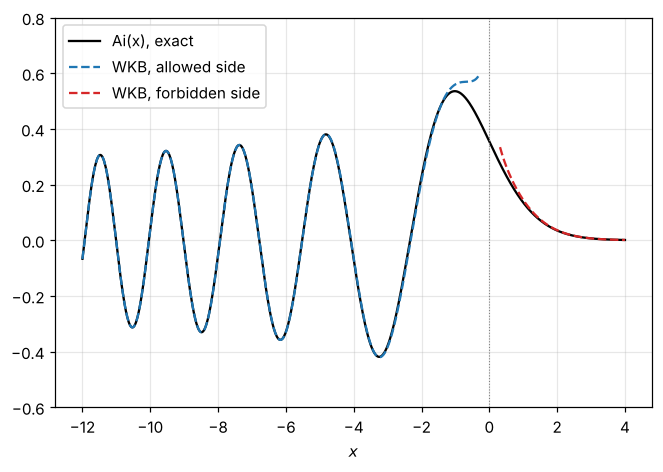

In [2]:
#| label: fig-airy-wkb
#| caption: "Near a turning point (here at x = 0, with V rising to the right as in ψ'' = xψ), the exact solution is the Airy function Ai (black). The WKB forms (dashed: oscillating on the left with the π/4 phase, decaying on the right) match it well a couple of units away but blow up at the turning point, where p → 0."
from scipy.special import airy
x = np.linspace(-12, 4, 800)
Ai = airy(x)[0]
xl = x[x < -0.3]; xr = x[x > 0.3]
wkb_l = np.sin(2 / 3 * (-xl)**1.5 + np.pi / 4) / (np.sqrt(np.pi) * (-xl)**0.25)
wkb_r = np.exp(-2 / 3 * xr**1.5) / (2 * np.sqrt(np.pi) * xr**0.25)
fig, ax = plt.subplots()
ax.plot(x, Ai, "k", label="Ai(x), exact")
ax.plot(xl, wkb_l, "--", color="tab:blue", label="WKB, allowed side")
ax.plot(xr, wkb_r, "--", color="tab:red", label="WKB, forbidden side")
ax.axvline(0, color="gray", lw=0.7, ls=":"); ax.set_ylim(-0.6, 0.8)
ax.set_xlabel("$x$"); ax.legend(); plt.show()

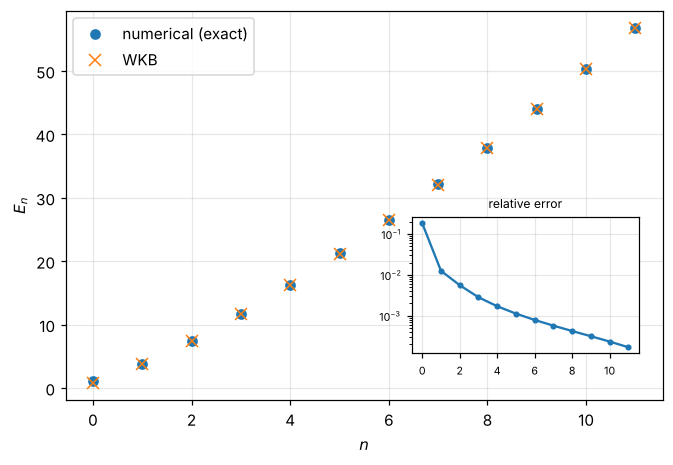

In [3]:
#| label: fig-wkb-quartic
#| caption: "Energies of the quartic oscillator V = x⁴ (ħ = 2m = 1, so p² = E − x⁴) from the WKB rule (orange) against an exact numerical diagonalization (blue). The relative error (inset) is 18% for the ground state, about 1% for n = 1, and keeps falling with n, as WKB is a large-quantum-number approximation."
from scipy.special import gamma as G
# WKB: integral of sqrt(E - x^4) from -E^(1/4) to E^(1/4) = c E^(3/4), c = 2 * integral_0^1 sqrt(1 - u^4) du
c_, _ = quad(lambda u: np.sqrt(1 - u**4), 0, 1); c_ *= 2
n = np.arange(12)
E_wkb = ((n + 0.5) * np.pi / c_)**(4 / 3)
# exact: finite differences for -psi'' + x^4 psi = E psi
L, Nx = 6.0, 2000
xs = np.linspace(-L, L, Nx); dx = xs[1] - xs[0]
H = np.diag(2 / dx**2 + xs**4) - np.diag(np.ones(Nx - 1) / dx**2, 1) - np.diag(np.ones(Nx - 1) / dx**2, -1)
E_ex = np.linalg.eigvalsh(H)[:12]
fig, ax = plt.subplots()
ax.plot(n, E_ex, "o", label="numerical (exact)"); ax.plot(n, E_wkb, "x", ms=8, label="WKB")
ax.set_xlabel("$n$"); ax.set_ylabel("$E_n$"); ax.legend(loc="upper left")
ins = ax.inset_axes([0.58, 0.12, 0.38, 0.35]); ins.semilogy(n, abs(E_wkb - E_ex) / E_ex, ".-"); ins.set_title("relative error", fontsize=8); ins.tick_params(labelsize=7)
plt.show()

### Tunneling

Through a barrier where $E < V$ between $x_1$ and $x_2$, the decaying WKB exponential gives a transmission probability

$$
T\approx\exp\!\left(-\frac2\hbar\int_{x_1}^{x_2}|p(x)|\,dx\right) .
$$ (eq-wkb-tunneling)

The exponent is what matters: the result is reliable when $T\ll1$. This one formula explains alpha decay (Gamow), field emission from metals, and the scanning tunneling microscope (quantum topic 9).

## Bessel and Spherical Bessel Functions

For a free particle in three dimensions, separating $\psi = R(r)Y_\ell^m$ with $u = rR$ gives

$$
u'' + \left[k^2 - \frac{\ell(\ell+1)}{r^2}\right]u = 0 .
$$ (eq-free-radial)

The solutions are $u = kr\,j_\ell(kr)$ and $kr\,n_\ell(kr)$, built from the **spherical Bessel functions**

$$
j_0(x) = \frac{\sin x}{x},\qquad n_0(x) = -\frac{\cos x}{x},\qquad
j_\ell(x) = (-x)^\ell\left(\frac1x\frac{d}{dx}\right)^\ell\frac{\sin x}{x} ,
$$ (eq-spherical-bessel)

and similarly for $n_\ell$. They are ordinary (cylindrical) Bessel functions of half-integer order, $j_\ell(x) = \sqrt{\pi/2x}\,J_{\ell+1/2}(x)$; cylindrical $J_\nu$ appear in problems with a symmetry axis, like a circular drum.

Their limits are what scattering uses:

$$
j_\ell(x)\approx\frac{x^\ell}{(2\ell+1)!!}\ \ (x\to0),\qquad
j_\ell(x)\approx\frac{\sin(x - \ell\pi/2)}{x}\ \ (x\to\infty) .
$$ (eq-jl-limits)

Near the origin, higher $\ell$ is suppressed like $x^\ell$: the centrifugal barrier keeps high-angular-momentum waves away from the center. Far away every $j_\ell$ is a sinusoid shifted by $\ell\pi/2$, and a potential shows up as an extra **phase shift** $\delta_\ell$.

**The plane wave in spherical waves (Rayleigh's formula).**

$$
e^{ikz} = e^{ikr\cos\theta} = \sum_{\ell=0}^\infty(2\ell + 1)\,i^\ell\,j_\ell(kr)\,P_\ell(\cos\theta) .
$$ (eq-rayleigh)

This is the starting point of partial-wave scattering.

In [4]:
xx = sp.symbols("x", positive=True)
for l in range(3):
    jl = sp.simplify(sp.expand_func(sp.jn(l, xx)))
    display(Math(rf"j_{l}(x) = " + sp.latex(jl)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

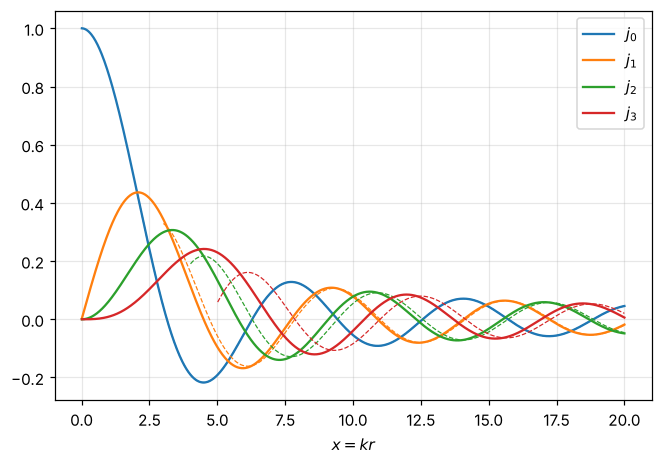

In [5]:
#| label: fig-spherical-bessel
#| caption: "Spherical Bessel functions j_ℓ(x) for ℓ = 0 to 3 (solid) with their large-x forms sin(x − ℓπ/2)/x (dashed). Higher ℓ starts like x^ℓ and stays near zero out to x ≈ ℓ: a wave with angular momentum ℓħ and wavenumber k barely reaches inside r ≈ ℓ/k."
from scipy.special import spherical_jn
X = np.linspace(0.01, 20, 800)
fig, ax = plt.subplots()
for l, col in zip(range(4), ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
    ax.plot(X, spherical_jn(l, X), color=col, label=f"$j_{l}$")
    Xa = X[X > l + 2]; ax.plot(Xa, np.sin(Xa - l * np.pi / 2) / Xa, "--", color=col, lw=0.8)
ax.set_xlabel("$x = kr$"); ax.legend(); plt.show()

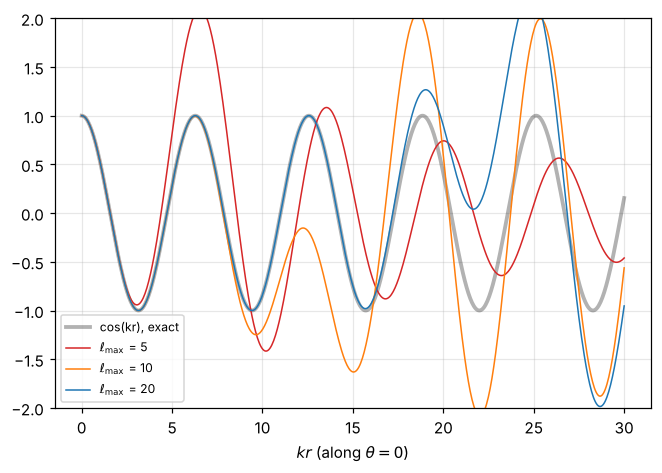

In [6]:
#| label: fig-rayleigh-convergence
#| caption: "Rayleigh's expansion of Re e^(ikz) along the z axis (θ = 0, where P_ℓ = 1), truncated at ℓ_max = 5, 10 and 20. A truncated sum reproduces the plane wave out to kr ≈ ℓ_max and then fails, which is why a short-range potential of size a needs only partial waves up to ℓ ≈ ka."
kr = np.linspace(0, 30, 600)
fig, ax = plt.subplots()
ax.plot(kr, np.cos(kr), "k", lw=2.5, alpha=0.3, label="cos(kr), exact")
for lmax, col in [(5, "tab:red"), (10, "tab:orange"), (20, "tab:blue")]:
    s = sum((2 * l + 1) * (1j**l) * spherical_jn(l, kr) for l in range(lmax + 1))
    ax.plot(kr, s.real, color=col, lw=1, label=f"$\\ell_{{\\max}}$ = {lmax}")
ax.set_ylim(-2, 2); ax.set_xlabel("$kr$ (along $\\theta = 0$)"); ax.legend(fontsize=8, loc="lower left"); plt.show()

### Exercises

1. Show that the WKB rule {eq}`eq-wkb-quantization` gives exactly $E_n = (n + \tfrac12)\hbar\omega$ for $V = \tfrac12m\omega^2x^2$.
2. Use {eq}`eq-wkb-tunneling` to find $T$ for a square barrier of height $V_0$ and width $a$, with $E < V_0$.
3. Apply WKB to the infinite square well. What goes wrong with the $\tfrac12$, and why?
4. Find $j_1(x)$ from the formula in {eq}`eq-spherical-bessel` and check both limits in {eq}`eq-jl-limits`.
5. An electron with 10 eV scatters from an atom of radius 0.1 nm. Roughly how many partial waves matter?

:::{dropdown} Hints
1. $\int_{-a}^ap\,dx$ is half the area of an ellipse in phase space: $\pi E/\omega$.
2. $|p|$ is constant inside.
3. The walls are not smooth turning points; $\psi$ must vanish there instead of decaying.
4. $\tfrac{d}{dx}(\sin x/x)$, times $-1$.
5. $\ell_{\max}\approx ka$ with $k = \sqrt{2mE}/\hbar$.
:::

:::{dropdown} Answers
1. $\int p\,dx = \pi E/\omega = (n + \tfrac12)\pi\hbar$, so $E = (n + \tfrac12)\hbar\omega$, exact.
2. $T\approx e^{-2\kappa a}$ with $\kappa = \sqrt{2m(V_0 - E)}/\hbar$, the leading behavior of the exact result.
3. With hard walls the rule becomes $\int p\,dx = n\pi\hbar$ ($n = 1, 2, \ldots$), the exact answer. The $\tfrac12$ comes from soft turning points' $\pi/4$ phases, which hard walls replace by $\pi/2$ each.
4. $j_1 = \sin x/x^2 - \cos x/x$; small $x$: $x/3$; large $x$: $-\cos x/x = \sin(x - \pi/2)/x$.
5. $k = 1.6\times10^{10}$ m⁻¹, $ka\approx1.6$: $\ell = 0$ and $1$ dominate, $\ell = 2$ a little.
:::

## Summary

- Find asymptotic behavior first and factor it out; asymptotic series improve as the variable grows even if they diverge.
- WKB: $\psi\approx p^{-1/2}e^{\pm i\int p\,dx/\hbar}$ where $V$ varies slowly; decaying exponentials under barriers give $T\approx e^{-2\int|p|dx/\hbar}$.
- Turning points need the Airy function; the connection formulas lead to $\int p\,dx = (n + \tfrac12)\pi\hbar$.
- Spherical Bessel $j_\ell$, $n_\ell$ solve the free radial equation; $j_\ell\sim x^\ell$ near 0 and $\sin(x - \ell\pi/2)/x$ far away. Rayleigh's formula expands a plane wave in them.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.